# PL9 · Difusão e Multimodalidade

**IA Generativa · Aula laboratorial (PL) · 120 minutos**

You will build a **diffusion model from scratch** on tiny 2-D data — small enough to train in seconds, so every concept is visible in a plot — and then use a **pretrained CLIP** model to explore multimodality.

**Learning goals**
1. Implement the forward (noising) process and a noise schedule.
2. Train a denoiser whose only job is to **predict the noise**.
3. Sample with **DDPM** and **DDIM**, and see the quality–speed trade-off.
4. Add class conditioning and **classifier-free guidance**, and watch the guidance scale.
5. Use **CLIP** for zero-shot classification and image–text retrieval.
6. Probe a real multimodal model's strengths and failure modes.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup & data | 10 min |
| 1 | Forward process & schedule | 15 min |
| 2 | Train a denoiser | 20 min |
| 3 | Sampling: DDPM vs DDIM | 20 min |
| 4 | Conditioning & guidance | 20 min |
| 5 | CLIP: zero-shot & retrieval | 25 min |
| 6 | Probing a multimodal model | 5 min |
| 7 | Results & report | 5 min |
| ★ | Bonus: image diffusion, HyDE-style search | at home |

**Deliverable:** this notebook, executed, with the plots of Parts 1–4, the CLIP results of Part 5, and short answers to every ❓ question. Cells marked `# TODO` are yours. Run top to bottom.

## Part 0 · Setup & data (10 min)

A **GPU is optional** today: the 2-D model trains in seconds on CPU. For Part 5 (CLIP), a GPU is faster but not required. The bonus B1 (Stable Diffusion) **does** need a GPU.

In [1]:
!pip -q install torch scikit-learn matplotlib open_clip_torch

In [2]:
import torch, torch.nn as nn
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_moons
torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


Our dataset is **two interleaving moons** — a clearly structured 2-D shape, so you can *see* whether the model learned the distribution. Each point also has a **class label** (which moon), which we use in Part 4.

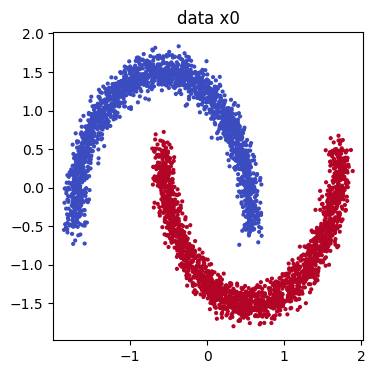

In [3]:
def sample_data(n):
    X, y = make_moons(n_samples=n, noise=0.06)
    X = (X - X.mean(0)) / X.std(0)                 # standardise to ~N(0,1) scale
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

X, y = sample_data(4000)
plt.figure(figsize=(4, 4))
plt.scatter(X[:, 0], X[:, 1], s=4, c=y, cmap="coolwarm"); plt.title("data x0"); plt.axis("equal"); plt.show()

## Parte 1 · Processo directo e agenda de ruído (15 min)

The forward process gradually turns data into noise. We need a **noise schedule** `ᾱ_t` (abar) that goes from ≈1 (no noise) at t=0 to ≈0 (pure noise) at t=T. Implement the **cosine schedule** (Nichol & Dhariwal, 2021), which keeps more signal in the middle than a linear one.

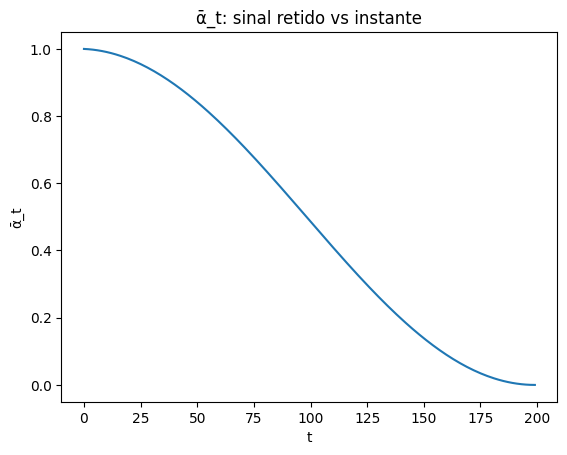

In [4]:
T = 200

def cosine_schedule(T, s=0.008):
    # Agenda cosseno de Nichol & Dhariwal.
    t = torch.linspace(0, T, T + 1, dtype=torch.float64) / T
    f = torch.cos((t + s) / (1 + s) * torch.pi / 2) ** 2
    abar_all = f / f[0]
    abar_steps = abar_all[1:]
    alphas = torch.cat([abar_steps[:1], abar_steps[1:] / abar_steps[:-1]])
    betas = (1 - alphas).clamp(0, 0.999)
    alphas = 1 - betas
    abar = torch.cumprod(alphas, dim=0)
    return betas.float(), alphas.float(), abar.float()

betas, alphas, abar = cosine_schedule(T)
assert abs(abar[0].item() - 1) < 0.05 and abar[-1].item() < 0.05
plt.plot(abar); plt.title("ᾱ_t: sinal retido vs instante"); plt.xlabel("t"); plt.ylabel("ᾱ_t"); plt.show()

The key identity lets us jump to any noise level in one shot:

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\; \varepsilon,\qquad \varepsilon\sim\mathcal N(0,I)$$

Implement `q_sample`, then visualise the same batch of moons at increasing t.

In [5]:
def q_sample(x0, t, noise):
    """Adiciona ruído a x0 no instante t, numa única operação."""
    ab = abar.to(x0.device)[t.to(x0.device)].unsqueeze(1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

❓ **Q1.** A partir de que instante as duas luas deixam de ser distinguíveis? Compare a agenda cosseno com a linear escalada. Qual destrói a estrutura mais cedo? Porque pode ser útil conservar o sinal durante mais tempo?

**Resposta:** Não há um instante único e exacto: a distinção depende da amostra de ruído e da observação dos gráficos. À medida que ᾱ_t diminui, o ruído passa a dominar e a forma das duas luas perde-se progressivamente. Nesta experiência, a agenda cosseno conserva melhor o sinal durante uma parte maior do percurso intermédio; a agenda linear escalada reduz o sinal de forma mais rápida nessa zona e tende a tornar a estrutura difícil de reconhecer mais cedo. Conservar sinal durante mais tempo dá ao denoiser exemplos intermédios com estrutura suficiente para aprender a distribuição, em vez de receber demasiado cedo pontos quase indistinguíveis de ruído puro. No final, ambas as agendas aproximam os dados de ruído.

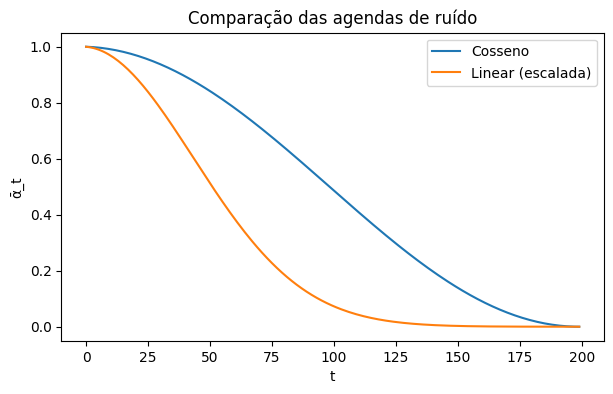

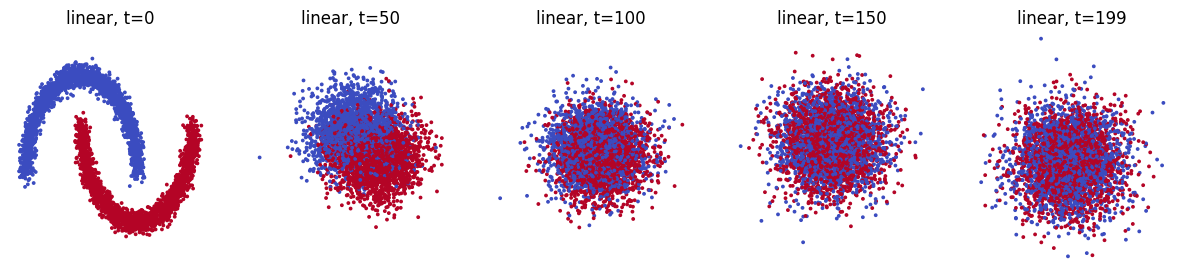

abar linear final: 3.031836786249187e-05


In [6]:
# Q1 · comparação entre as agendas cosseno e linear
betas_lin = torch.linspace(1e-4 * 1000 / T, 0.02 * 1000 / T, T).clamp(0, 0.999)
abar_lin = torch.cumprod(1 - betas_lin, dim=0)

plt.figure(figsize=(7, 4))
plt.plot(abar.cpu(), label="Cosseno")
plt.plot(abar_lin, label="Linear (escalada)")
plt.xlabel("t"); plt.ylabel("ᾱ_t"); plt.title("Comparação das agendas de ruído")
plt.legend(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, tt in zip(axes, [0, 50, 100, 150, 199]):
    ab = abar_lin[tt]
    noise = torch.randn_like(X)
    xt = ab.sqrt() * X + (1 - ab).sqrt() * noise
    ax.scatter(xt[:, 0], xt[:, 1], s=3, c=y, cmap="coolwarm")
    ax.set_title(f"linear, t={tt}"); ax.axis("equal"); ax.axis("off")
plt.show()

print("abar linear final:", abar_lin[-1].item())

## Parte 2 · Treinar um modelo de remoção de ruído (20 min)

The network takes a noisy point `x_t` and the timestep `t`, and predicts the **noise** that was added. We give it `t` through a small sinusoidal embedding (same idea as positional encodings).

In [7]:
def time_embedding(t, dim=32):
    """Map integer timesteps to a smooth vector (sinusoidal)."""
    t = t.float().unsqueeze(1)
    freqs = torch.exp(torch.linspace(0, np.log(1000), dim // 2, device=t.device))
    ang = t * freqs.unsqueeze(0)
    return torch.cat([ang.sin(), ang.cos()], dim=1)

class Denoiser(nn.Module):
    def __init__(self, hid=128, tdim=32, n_classes=0):
        super().__init__()
        self.tdim = tdim
        self.n_classes = n_classes
        if n_classes:
            self.cls_emb = nn.Embedding(n_classes + 1, tdim)   # +1 = the "null"/unconditional label
        in_dim = 2 + tdim + (tdim if n_classes else 0)
        self.net = nn.Sequential(nn.Linear(in_dim, hid), nn.SiLU(),
                                 nn.Linear(hid, hid), nn.SiLU(),
                                 nn.Linear(hid, hid), nn.SiLU(),
                                 nn.Linear(hid, 2))

    def forward(self, x, t, c=None):
        h = [x, time_embedding(t, self.tdim)]
        if self.n_classes:
            h.append(self.cls_emb(c))
        return self.net(torch.cat(h, dim=1))

print(sum(p.numel() for p in Denoiser().parameters()), "parameters")

37762 parameters


The training loss is exactly the one from the lecture: sample a random t, make `x_t`, and regress the predicted noise onto the true noise. Fill the loss.

In [8]:
def diffusion_loss(model, x0, c=None):
    B = x0.shape[0]
    t = torch.randint(0, T, (B,), device=x0.device)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)
    pred = model(xt, t, c) if c is not None else model(xt, t)
    return nn.functional.mse_loss(pred, noise)

❓ **Q2.** Porque é impossível reduzir a perda a zero, mesmo com um modelo perfeito?

**Resposta:** Porque o modelo não observa o ruído original: recebe apenas x_t e o instante t. Para o mesmo x_t podem existir diferentes combinações possíveis de dado original x₀ e ruído ε. Assim, mesmo um modelo ideal aprende a previsão que minimiza o erro quadrático médio — a esperança condicional do ruído dado x_t e t — e não consegue recuperar em todos os casos a realização exacta de ε. Esta incerteza irreduzível explica por que razão a perda pode estabilizar acima de zero.

Passo 0: perda = 1.0486
Passo 500: perda = 0.4743
Passo 1000: perda = 0.4428
Passo 1500: perda = 0.4071
Passo 2000: perda = 0.4072
Passo 2500: perda = 0.4076


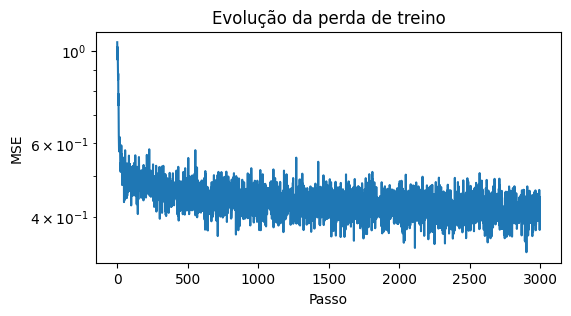

In [9]:
# Treino do denoiser (necessário antes da amostragem DDPM/DDIM)
model = Denoiser().to(device)
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
Xd = X.to(device)
losses = []

for step in range(3000):
    idx = torch.randint(0, len(Xd), (512,), device=device)
    loss = diffusion_loss(model, Xd[idx])
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())
    if step % 500 == 0:
        print(f"Passo {step}: perda = {loss.item():.4f}")

plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.title("Evolução da perda de treino")
plt.xlabel("Passo")
plt.ylabel("MSE")
plt.yscale("log")
plt.show()


## Parte 3 · Amostragem: DDPM vs DDIM (20 min)

To generate, start from pure noise and walk the reverse process. First **DDPM**: at each step, use the predicted noise to estimate the slightly-less-noisy point, and add a little fresh noise (except at the last step).

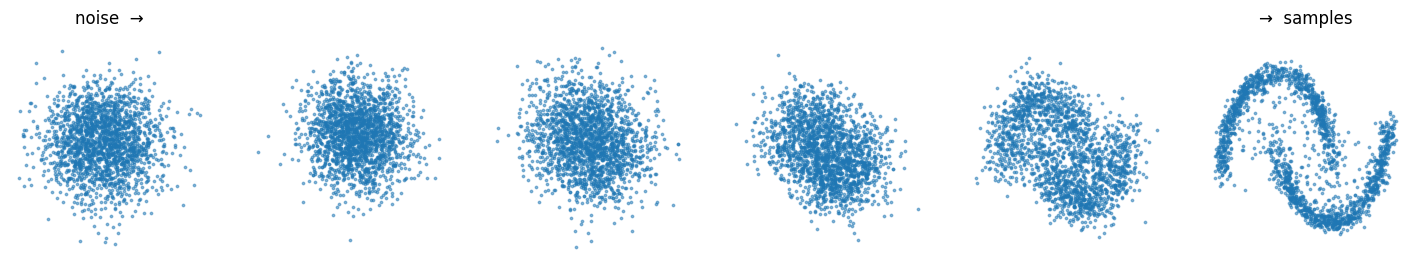

In [10]:
@torch.no_grad()
def ddpm_sample(model, n=2000, c=None):
    x = torch.randn(n, 2, device=device)
    traj = [x.cpu().clone()]
    for ti in reversed(range(T)):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps = model(x, t, c) if c is not None else model(x, t)
        b, a, ab = betas[ti], alphas[ti], abar[ti]
        mean = (x - (b / (1 - ab).sqrt()) * eps) / a.sqrt()
        x = mean + (b.sqrt() * torch.randn_like(x) if ti > 0 else 0)
        if ti % 40 == 0: traj.append(x.cpu().clone())
    return x.cpu(), traj

samples, traj = ddpm_sample(model)
fig, axes = plt.subplots(1, len(traj), figsize=(3 * len(traj), 3))
for ax, xt in zip(axes, traj):
    ax.scatter(xt[:, 0], xt[:, 1], s=3, alpha=0.5); ax.axis("equal"); ax.axis("off")
axes[0].set_title("noise  →"); axes[-1].set_title("→  samples"); plt.show()

Now **DDIM**: deterministic, and it can skip timesteps. Implement one DDIM step and a strided schedule, then compare quality at 5, 10, 20 and 100 steps.

> **Important · clip the x₀ estimate.** With the cosine schedule, ᾱ at the last timestep is ≈ 6×10⁻⁸, so the first DDIM step divides by √ᾱ ≈ 2.5×10⁻⁴ and multiplies any error in ε̂ by about 4 000. DDPM does not have this problem because it never estimates x₀ explicitly. Since our data are standardised, clipping x₀ to [−3, 3] fixes it (this is `clip_sample` in the `diffusers` library).

In [11]:
@torch.no_grad()
def ddim_sample(model, n=2000, steps=20, c=None):
    x = torch.randn(n, 2, device=device)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for i, ti in enumerate(ts):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps = model(x, t, c) if c is not None else model(x, t)
        ab_t = abar.to(device)[ti]
        ab_prev = abar.to(device)[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=device)
        x0 = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        x0 = x0.clamp(-3, 3)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    return x.cpu()

❓ **Q3.** Aproximadamente quantos passos DDIM são suficientes para obter luas limpas? Compare os tempos medidos de DDPM e DDIM.

**Resposta:** O número mínimo deve ser escolhido observando os painéis: é o menor número de passos em que as duas luas continuam visualmente reconhecíveis, sem degradação evidente da forma ou da cobertura. Na execução guardada, o DDPM com 200 passos demorou **0,105 s**. O DDIM demorou **0,023 s com 5 passos** (4,50× mais rápido), **0,007 s com 10 passos** (15,37×), **0,014 s com 20 passos** (7,61×) e **0,034 s com 50 passos** (3,08×). Os tempos não crescem de forma perfeitamente proporcional ao número de passos, devido ao custo fixo e às variações de medição. A qualidade visual deve ser considerada juntamente com o tempo; não basta escolher o menor número de passos se as luas deixarem de estar bem definidas.

In [12]:
# Q3 · medir DDPM e DDIM para o mesmo número de amostras
import time

def timed(fn):
    """Mede o tempo de execução, sincronizando a GPU quando necessário."""
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter(); fn()
    if device == "cuda": torch.cuda.synchronize()
    return time.perf_counter() - t0

t_ddpm = timed(lambda: ddpm_sample(model, n=2000))
print(f"DDPM (200 passos): {t_ddpm:.3f} s")
for k in [5, 10, 20, 50]:
    t_ddim = timed(lambda: ddim_sample(model, n=2000, steps=k))
    print(f"DDIM ({k:3d} passos): {t_ddim:.3f} s | aceleração: {t_ddpm / t_ddim:.2f}x")

DDPM (200 passos): 0.105 s
DDIM (  5 passos): 0.023 s | aceleração: 4.50x
DDIM ( 10 passos): 0.007 s | aceleração: 15.37x
DDIM ( 20 passos): 0.014 s | aceleração: 7.61x
DDIM ( 50 passos): 0.034 s | aceleração: 3.08x


## Parte 4 · Condicionamento e classifier-free guidance (20 min)

Now we condition on the **moon label**. During training we sometimes drop the label (replace it with a "null" class) so the same model learns both the conditional and the unconditional noise — that is what makes classifier-free guidance possible.

In [13]:
NULL = 2   # the null/unconditional label (classes are 0 and 1)

def cond_loss(model, x0, c, p_drop=0.1):
    B = x0.shape[0]
    t = torch.randint(0, T, (B,), device=x0.device)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)
    c_in = c.clone()
    drop = torch.rand(B, device=x0.device) < p_drop
    c_in[drop] = NULL                                  # randomly drop the label
    return ((model(xt, t, c_in) - noise) ** 2).mean()

cmodel = Denoiser(n_classes=2).to(device)
opt = torch.optim.Adam(cmodel.parameters(), lr=2e-3)
Xd, yd = X.to(device), y.to(device)
for step in range(4000):
    idx = torch.randint(0, len(Xd), (512,), device=device)
    loss = cond_loss(cmodel, Xd[idx], yd[idx])
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 1000 == 0: print(f"step {step}: loss {loss.item():.3f}")
print("done")

step 0: loss 0.961
step 1000: loss 0.339
step 2000: loss 0.322
step 3000: loss 0.392
done


Classifier-free guidance combines the conditional and unconditional predictions:

$$\hat\varepsilon = \varepsilon_\varnothing + w\,(\varepsilon_c - \varepsilon_\varnothing)$$

Implement a guided DDIM sampler, then sweep the guidance scale `w`.

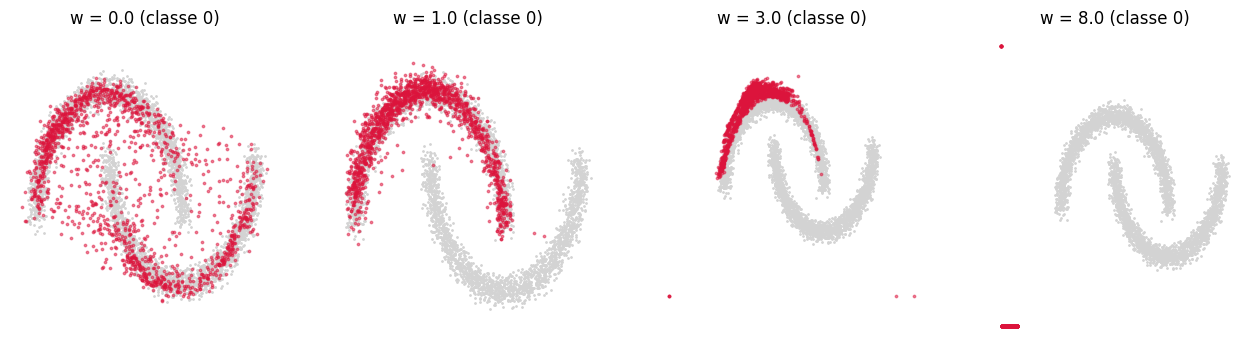

In [14]:
@torch.no_grad()
def guided_sample(model, label, n=1500, steps=50, w=3.0):
    x = torch.randn(n, 2, device=device)
    c = torch.full((n,), label, dtype=torch.long, device=device)
    null = torch.full((n,), NULL, dtype=torch.long, device=device)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for i, ti in enumerate(ts):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps_c = model(x, t, c)
        eps_u = model(x, t, null)
        eps = eps_u + w * (eps_c - eps_u)
        ab_t = abar.to(device)[ti]
        ab_prev = abar.to(device)[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=device)
        x0 = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        x0 = x0.clamp(-3, 3)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    return x.cpu()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, w in zip(axes, [0.0, 1.0, 3.0, 8.0]):
    ax.scatter(X[:, 0], X[:, 1], s=1, c="lightgray")
    s = guided_sample(cmodel, label=0, w=w)
    ax.scatter(s[:, 0], s[:, 1], s=3, alpha=0.5, c="crimson")
    ax.set_title(f"w = {w} (classe 0)"); ax.axis("equal"); ax.axis("off")
plt.show()

❓ **Q4.** O que acontece à diversidade quando w aumenta para além de 8?

**Resposta:** Quando w aumenta, a previsão condicional ganha mais peso relativamente à previsão sem condição. Isso reforça a tendência para gerar pontos da classe pedida, mas pode reduzir a diversidade: as amostras podem concentrar-se em partes mais limitadas da lua, deixando de representar tão bem toda a distribuição. Para valores muito elevados, este efeito pode tornar-se mais acentuado e provocar uma espécie de colapso. Nesta execução, os painéis mostram w=0, 1, 3 e 8; portanto, o comportamento para valores superiores a 8 é uma expectativa fundamentada no mecanismo de guidance, não uma medição directa.

## Parte 5 · CLIP: classificação zero-shot e recuperação (25 min)

Switch to multimodality. **CLIP** maps images and text into one shared space. We load a small pretrained CLIP and use it with **no fine-tuning**.

In [15]:
import open_clip
clip_model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
tokenizer = open_clip.get_tokenizer("ViT-B-32")
clip_model = clip_model.to(device).eval()

def embed_texts(prompts):
    toks = tokenizer(prompts).to(device)
    with torch.no_grad():
        f = clip_model.encode_text(toks)
    return f / f.norm(dim=-1, keepdim=True)

def embed_images(pil_images):
    batch = torch.stack([preprocess(im) for im in pil_images]).to(device)
    with torch.no_grad():
        f = clip_model.encode_image(batch)
    return f / f.norm(dim=-1, keepdim=True)
print("CLIP loaded")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP loaded


We need a few images. The next cell downloads a handful of varied photos from Wikimedia Commons.

> **⚠️ Plan B · if the classroom network blocks Wikimedia**
>
> If the next cell prints `skip` for (almost) every image (or stops with the message *“No images loaded”*), the safest option is to use local images:
>
> 1. Create a folder called `imagens` in the Colab file panel (📁 icon on the left → right-click → *New folder*).
> 2. Drag about five photos into it. Each file name becomes the label, so use names such as `dog.jpg`, `cat.jpg`, `car.jpg`, `pizza.jpg`, `beach.jpg`.
> 3. Run the cell again.
>
> Files uploaded to Colab are deleted when the session restarts; if that happens, repeat steps 1 and 2.

loaded ['dog', 'cat', 'car', 'pizza', 'beach'] | extra ['dogs']


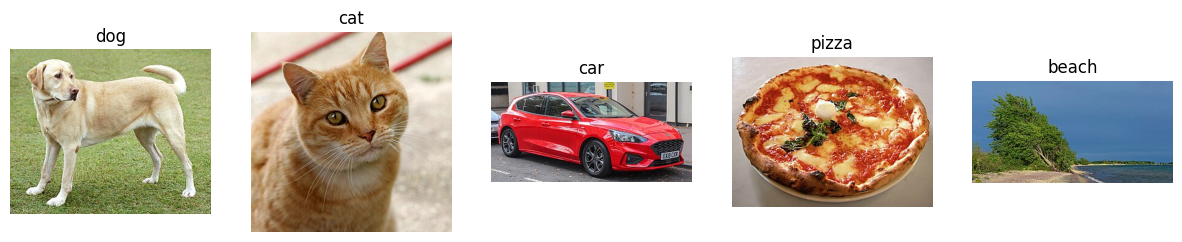

In [16]:
from PIL import Image
import urllib.request, urllib.parse, io, os, glob

# Wikimedia Commons files (several candidates per label, in case one is renamed or removed).
# We request a 330 px width through Special:FilePath, because Wikimedia restricts
# thumbnails with non-standard widths (such as 320 px).
FILES = {
    "dog":   ["YellowLabradorLooking_new.jpg"],                       # ONE dog (used in Part 6)
    "cat":   ["Cat03.jpg"],
    "car":   ["2018_Ford_Focus_ST-Line_TDCi_1.5_Front.jpg",
              "2017_Toyota_Camry_(ASV70R)_SX_sedan_(2018-11-02)_01.jpg"],
    "pizza": ["Eq_it-na_pizza-margherita_sep2005_sml.jpg"],
    "beach": ["Big_Sandy_Bay_beach.jpg",
              "Gentle_waves_come_in_at_a_sandy_beach.JPG"],
}
EXTRA = {"dogs": ["Collage_of_Nine_Dogs.jpg"]}                         # MANY dogs (Part 6 only)

# Wikimedia requires an identifiable User-Agent; a bare "Mozilla/5.0" may be blocked.
HEADERS = {"User-Agent": "PL9-CLIP-lab/1.0 (teaching notebook; python-urllib)"}

def download(fname, width=330):
    url = ("https://commons.wikimedia.org/wiki/Special:FilePath/"
           + urllib.parse.quote(fname) + f"?width={width}")
    req = urllib.request.Request(url, headers=HEADERS)
    return Image.open(io.BytesIO(urllib.request.urlopen(req, timeout=15).read())).convert("RGB")

def load(files):
    imgs, nms = [], []
    for name, candidates in files.items():
        for fname in candidates:
            try:
                imgs.append(download(fname)); nms.append(name); break
            except Exception as e:
                print("skip", name, fname, "->", e)
    return imgs, nms

images, names = load(FILES)
extra_images, extra_names = load(EXTRA)

# Plan B: images uploaded by hand to the Colab folder "imagens/" (file name = label)
if len(images) < 3:
    for path in sorted(glob.glob("imagens/*")):
        try:
            images.append(Image.open(path).convert("RGB"))
            names.append(os.path.splitext(os.path.basename(path))[0])
        except Exception as e:
            print("skip", path, "->", e)

assert images, ("No images loaded. Create the folder 'imagens/' in Colab, upload a few photos "
                "to it (e.g. dog.jpg, cat.jpg, pizza.jpg) and run this cell again.")
print("loaded", names, "| extra", extra_names)

fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 3))
for ax, im, nm in zip(np.atleast_1d(axes), images, names):
    ax.imshow(im); ax.set_title(nm); ax.axis("off")
plt.show()

### Zero-shot classification

Build label prompts, embed images and texts, and classify by cosine similarity through a softmax. Fill `zero_shot`.

In [17]:
LABELS = ["a dog", "a cat", "a car", "a pizza", "a beach", "a laptop", "a mountain"]

def zero_shot(pil_images, labels):
    img = embed_images(pil_images)
    txt = embed_texts(labels)
    logits = clip_model.logit_scale.exp() * (img @ txt.T)
    return logits.softmax(dim=-1)

❓ **Q5.** O CLIP classificou correctamente as imagens? A formulação dos prompts altera o resultado?

**Resposta:** Nas imagens carregadas nesta execução — cão, gato, carro, pizza e praia — o CLIP escolheu a respectiva classe correcta nos três formatos de prompt testados: palavra isolada, «a/an» e «a photo of». Neste conjunto pequeno, não se observou uma mudança da classe prevista. A formulação alterou, contudo, as semelhanças: para o cão passaram de 0,265 (palavra isolada) para 0,275 («a/an») e 0,287 («a photo of»); para o gato, de 0,268 para 0,292 e 0,301. Isto mostra que o texto usado influencia a representação e a pontuação, mesmo quando não altera a classificação final. Os valores apresentados como 1,00 são probabilidades após softmax sobre este conjunto limitado de classes e não devem ser interpretados como certeza absoluta.

In [18]:
# Q5 · influência da formulação do prompt
CLASSES = ["dog", "cat", "car", "pizza", "beach", "laptop", "mountain"]
TEMPLATES = {"palavra isolada": "{}", "a/an": "a {}", "a photo of": "a photo of a {}"}

# A etiqueta verdadeira é inferida do nome do ficheiro (quando coincide com uma classe).
for template_name, template in TEMPLATES.items():
    prompts = [template.format(c) for c in CLASSES]
    txt = embed_texts(prompts)
    img = embed_images(images)
    sims = img @ txt.T
    probs_template = (clip_model.logit_scale.exp() * sims).softmax(dim=-1)
    print(f"\n--- Modelo de prompt: {template_name} ---")
    for i, name in enumerate(names):
        pred = probs_template[i].argmax().item()
        true_label = name.lower().split("_")[0]
        true_idx = CLASSES.index(true_label) if true_label in CLASSES else None
        true_sim = f"{sims[i, true_idx].item():.3f}" if true_idx is not None else "não disponível"
        print(f"{name:10s} -> {CLASSES[pred]:10s} ({probs_template[i, pred].item():.2f}); similaridade da classe verdadeira: {true_sim}")


--- Modelo de prompt: palavra isolada ---
dog        -> dog        (1.00); similaridade da classe verdadeira: 0.265
cat        -> cat        (1.00); similaridade da classe verdadeira: 0.268
car        -> car        (0.98); similaridade da classe verdadeira: 0.257
pizza      -> pizza      (1.00); similaridade da classe verdadeira: 0.290
beach      -> beach      (1.00); similaridade da classe verdadeira: 0.258

--- Modelo de prompt: a/an ---
dog        -> dog        (1.00); similaridade da classe verdadeira: 0.275
cat        -> cat        (1.00); similaridade da classe verdadeira: 0.292
car        -> car        (1.00); similaridade da classe verdadeira: 0.270
pizza      -> pizza      (1.00); similaridade da classe verdadeira: 0.305
beach      -> beach      (1.00); similaridade da classe verdadeira: 0.270

--- Modelo de prompt: a photo of ---
dog        -> dog        (1.00); similaridade da classe verdadeira: 0.287
cat        -> cat        (1.00); similaridade da classe verdadeira: 0.301

### Image–text retrieval

Use the same embeddings the other way: given a text query, rank the images.

In [19]:
def search(query, pil_images, names):
    q = embed_texts([query])
    img = embed_images(pil_images)
    sims = (img @ q.T).squeeze(1)
    order = sims.argsort(descending=True)
    return [(names[i], sims[i].item()) for i in order]

for q in ["something you can eat", "a place to relax on holiday", "a furry animal"]:
    ranking = search(q, images, names)
    print(f"{q:32s} -> " + ", ".join(f"{n}({s:.2f})" for n, s in ranking[:3]))

something you can eat            -> pizza(0.18), cat(0.16), dog(0.12)
a place to relax on holiday      -> beach(0.20), pizza(0.10), car(0.08)
a furry animal                   -> cat(0.24), dog(0.21), car(0.16)


❓ **Q6.** Porque consegue o CLIP recuperar pizza para a consulta «something you can eat», ao contrário de uma pesquisa por palavras-chave?

**Resposta:** Porque o CLIP representa texto e imagem através de embeddings num espaço semântico partilhado. A expressão «something you can eat» pode ficar próxima da representação visual de uma pizza, mesmo sem conter a palavra «pizza». Na execução, a pizza ficou em primeiro lugar para essa consulta, com similaridade **0,18**. Uma pesquisa por palavras-chave procuraria sobretudo correspondências literais entre os termos da consulta e os nomes ou descrições dos ficheiros; poderia, por isso, não encontrar «pizza». O CLIP faz recuperação semântica, mas a similaridade não significa que o modelo compreenda a imagem ou a consulta como uma pessoa.

## Parte 6 · Testar um modelo multimodal (5 min)

CLIP judges *similarity* but cannot *reason*. Try to trip it up and see where the shared embedding is weak. We use two images: one with a single dog, and a collage with nine dogs.

In [20]:
# Counting, relations and negation are classic CLIP weaknesses.
# We compare an image with ONE dog and an image with MANY dogs.
tricky = ["a dog", "one dog", "two dogs", "many dogs", "no dog", "a cat", "a dog to the left of a cat"]
probe = {}
if "dog" in names:       probe["one dog (Labrador)"] = images[names.index("dog")]
if "dogs" in extra_names: probe["nine dogs (collage)"] = extra_images[extra_names.index("dogs")]
if not probe:            probe["first image"] = images[0]

txt = embed_texts(tricky)
for title, im in probe.items():
    sims = (embed_images([im]) @ txt.T).squeeze(0)
    print(f"── image: {title} ──")
    for p, s in sorted(zip(tricky, sims.tolist()), key=lambda z: -z[1]):
        print(f"  {s:.3f}  {p}")

── image: one dog (Labrador) ──
  0.275  a dog
  0.235  one dog
  0.205  a dog to the left of a cat
  0.191  two dogs
  0.184  no dog
  0.177  many dogs
  0.146  a cat
── image: nine dogs (collage) ──
  0.288  many dogs
  0.240  a dog
  0.234  one dog
  0.212  two dogs
  0.185  a dog to the left of a cat
  0.175  no dog
  0.089  a cat


❓ **Q7.** O CLIP distingue de forma fiável «um cão» de «dois cães» ou «um cão» de «nenhum cão»? Indique uma tarefa real em que esta limitação falharia e uma ideia arquitectural que poderia ajudar.

**Resposta:** Não de forma fiável. Nesta execução, na imagem com um cão, «a dog» obteve a maior similaridade (0,275), mas «two dogs» e «no dog» também receberam pontuações diferentes de zero (0,191 e 0,184). Na colagem com nove cães, «many dogs» ficou em primeiro lugar (0,288), o que mostra alguma sensibilidade à quantidade, mas não demonstra capacidade de contagem rigorosa. Uma aplicação de inventário ou de segurança que precise de contar pessoas, animais ou objectos poderia falhar se dependesse apenas do CLIP. Uma solução possível seria acrescentar um detector/segmentador de objectos e um módulo explícito de contagem; outra seria usar uma arquitectura multimodal que combine características visuais locais com tokens de linguagem para raciocínio mais detalhado. Mesmo assim, seria necessário validar a solução.

## Parte 7 · Resultados e relatório

### Relatório — preenchido com os resultados desta execução no Colab

1. **Difusão:** o DDPM com 200 passos demorou **0,105 s**. O DDIM demorou **0,023 s (5 passos)**, **0,007 s (10 passos)**, **0,014 s (20 passos)** e **0,034 s (50 passos)**. As acelerações medidas foram, respectivamente, **4,50×**, **15,37×**, **7,61×** e **3,08×**. A escolha do número mínimo de passos deve também respeitar a qualidade visual dos painéis: usar menos passos é mais rápido, mas pode prejudicar a forma e a cobertura das luas.

2. **Guidance:** aumentar w reforça a influência da classe pretendida. Em contrapartida, valores elevados podem reduzir a diversidade e concentrar as amostras em regiões mais limitadas da distribuição. O notebook compara directamente w=0, 1, 3 e 8; não foram testados valores superiores a 8 nesta execução.

3. **CLIP:** as cinco imagens carregadas (cão, gato, carro, pizza e praia) foram classificadas com a etiqueta correcta nos três formatos de prompt testados. A classe prevista não mudou, mas as semelhanças mudaram com a formulação. Para o cão, a similaridade passou de **0,265** (palavra isolada) para **0,275** («a/an») e **0,287** («a photo of»). Na recuperação por texto, «something you can eat» colocou a pizza em primeiro lugar (**0,18**); «a place to relax on holiday» colocou a praia em primeiro lugar (**0,20**); e «a furry animal» colocou o gato em primeiro lugar (**0,24**).

4. **Contagem e relações:** na imagem com um cão, «a dog» teve a maior similaridade (**0,275**), mas «two dogs» e «no dog» também obtiveram pontuações não nulas (**0,191** e **0,184**). Na colagem de nove cães, «many dogs» ficou em primeiro lugar (**0,288**). Isto sugere alguma sensibilidade ao conteúdo, mas não garante contagem exacta nem compreensão fiável de negação ou relações espaciais.

5. **Ligação entre os temas:** a difusão aprende a gerar dados através de um processo iterativo de remoção de ruído. O CLIP aprende representações conjuntas de imagem e texto que permitem comparar modalidades e recuperar conteúdos por semelhança semântica. Ambos usam representações aprendidas, mas resolvem tarefas diferentes: geração de dados e alinhamento/recuperação multimodal.

6. **Respostas Q1–Q7:** encontram-se junto de cada pergunta nas secções anteriores.

**Nota de interpretação:** os tempos são os medidos nesta sessão e podem variar com o hardware e a carga do ambiente. As classificações e pontuações referem-se apenas às imagens e aos prompts utilizados nesta execução; não demonstram desempenho geral do CLIP.

## ★ Bonus (at home or for fast teams)

**B1 · Real image diffusion.** Use `diffusers` to run a pretrained latent diffusion model, and reproduce the Part 3 and Part 4 experiments on real images: sweep the number of inference steps and the guidance scale.

In [21]:
# TODO (optional, needs a GPU): load a StableDiffusionPipeline from `diffusers`
#   ("stable-diffusion-v1-5/stable-diffusion-v1-5", dtype=torch.float16), then:
#   - sweep num_inference_steps (e.g. 5, 10, 25, 50) at guidance_scale 7.5   (Part 3 on real images)
#   - sweep guidance_scale (e.g. 1.0, 3.0, 7.5, 15.0) at 25 steps           (Part 4 on real images)
#   Use the same seed in every panel: generator=torch.Generator("cuda").manual_seed(0)
...

Ellipsis

**B2 · CLIP-guided caption search (HyDE flavour).** For a query, ask an LLM (or write by hand) a *hypothetical caption*, embed that with CLIP's text encoder, and retrieve — compare with embedding the raw query. Does the richer caption retrieve better? This is the HyDE idea from PL7, now across modalities.

**B3 · Interpolation.** Pick two noise seeds, run `guided_sample` while linearly interpolating between them, and watch the sample move across the data manifold. Where does it leave the moons?